Đang tải dữ liệu lịch sử các ETF...


[*********************100%***********************]  5 of 5 completed



--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN ---
Ticker       SPY       TLT       GLD       DBC       VNQ
Ticker                                                  
SPY     1.000000  0.127599  0.201484  0.086220  0.496310
TLT     0.127599  1.000000  0.124715 -0.198422  0.417783
GLD     0.201484  0.124715  1.000000  0.269712  0.172701
DBC     0.086220 -0.198422  0.269712  1.000000 -0.025523
VNQ     0.496310  0.417783  0.172701 -0.025523  1.000000


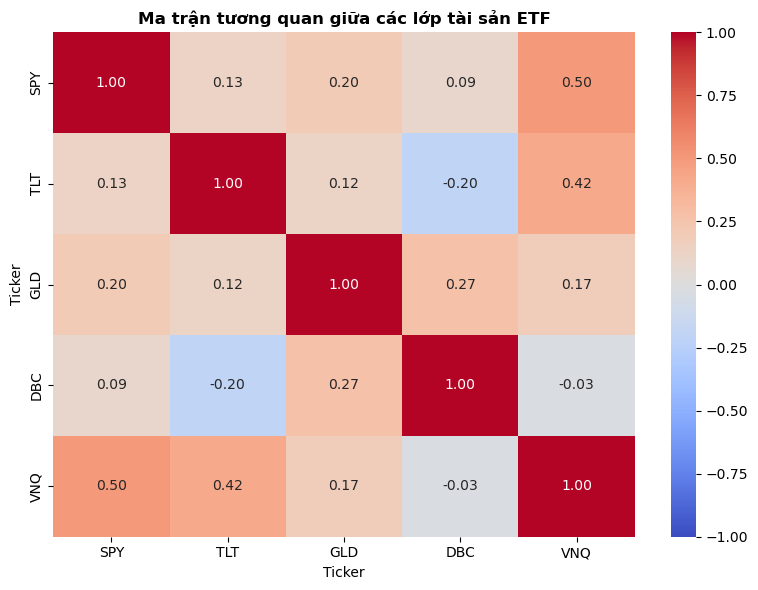


--- TRỌNG SỐ DANH MỤC RISK PARITY (INVERSE VOLATILITY) ---
- SPY: 21.23%
- TLT: 25.41%
- GLD: 14.82%
- DBC: 18.76%
- VNQ: 19.77%


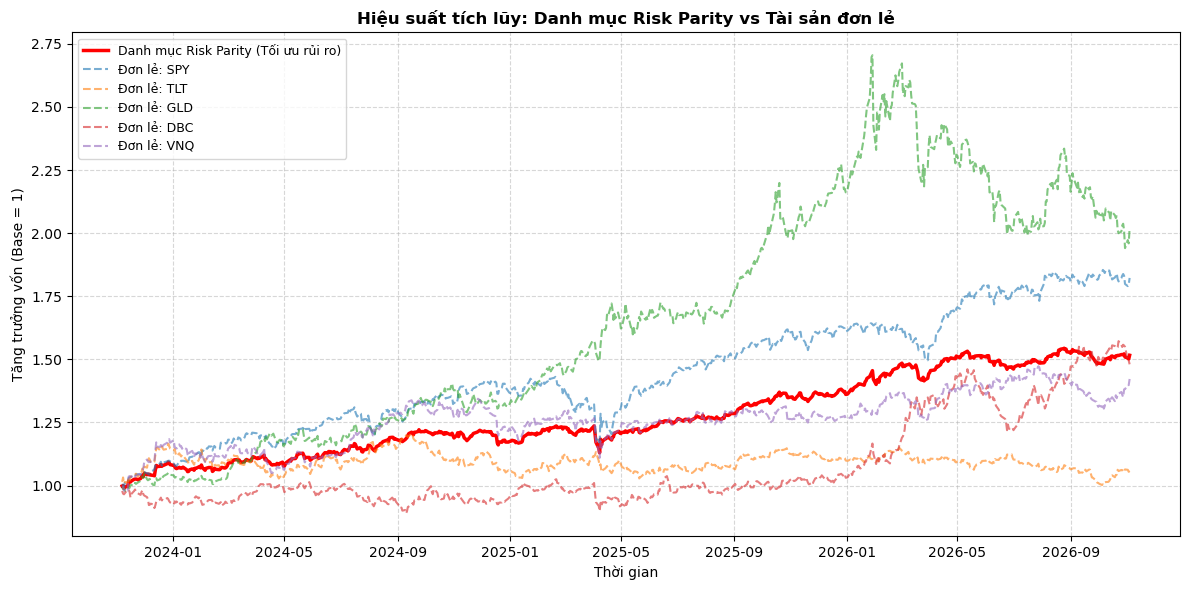

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# 1. Định nghĩa rổ ETF đại diện cho các lớp tài sản phi tương quan
# SPY: Cổ phiếu Mỹ, TLT: Trái phiếu dài hạn, GLD: Vàng, DBC: Hàng hóa, VNQ: Bất động sản
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]

print("Đang tải dữ liệu lịch sử các ETF...")
data = yf.download(tickers, period="3y", interval="1d", auto_adjust=True)


# Lấy dữ liệu giá đóng cửa (Close)
def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()

# 2. Tính tỷ suất sinh lợi hàng ngày (Daily Returns)
returns = prices.pct_change().dropna()

# 3. Tính và hiển thị Ma trận tương quan (Correlation Matrix)
corr_matrix = returns.corr()
print("\n--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN ---")
print(corr_matrix)

# Vẽ biểu đồ nhiệt (Heatmap) ma trận tương quan
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title(
    "Ma trận tương quan giữa các lớp tài sản ETF", fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.show()

# 4. Tính toán phân bổ Risk-Parity cơ bản (Inverse Volatility Weighting)
# Trọng số tỷ lệ nghịch với độ biến động (Standard Deviation) của từng tài sản
volatilities = returns.std()
inv_vol = 1.0 / volatilities
risk_parity_weights = inv_vol / np.sum(inv_vol)

print("\n--- TRỌNG SỐ DANH MỤC RISK PARITY (INVERSE VOLATILITY) ---")
for ticker, weight in risk_parity_weights.items():
  print(f"- {ticker}: {weight*100:.2f}%")

# 5. Kiểm tra hiệu suất danh mục so với từng tài sản đơn lẻ
portfolio_returns = (returns * risk_parity_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục Risk Parity (Tối ưu rủi ro)",
    color="red",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.6,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy: Danh mục Risk Parity vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF từ năm 2007 để kiểm chứng giai đoạn khủng hoảng...


[*********************100%***********************]  5 of 5 completed



--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN (2007 - NAY) ---
Ticker       SPY       TLT       GLD       DBC       VNQ
Ticker                                                  
SPY     1.000000 -0.305724  0.068746  0.391115  0.744770
TLT    -0.305724  1.000000  0.164994 -0.235425 -0.155512
GLD     0.068746  0.164994  1.000000  0.336378  0.058896
DBC     0.391115 -0.235425  0.336378  1.000000  0.264375
VNQ     0.744770 -0.155512  0.058896  0.264375  1.000000


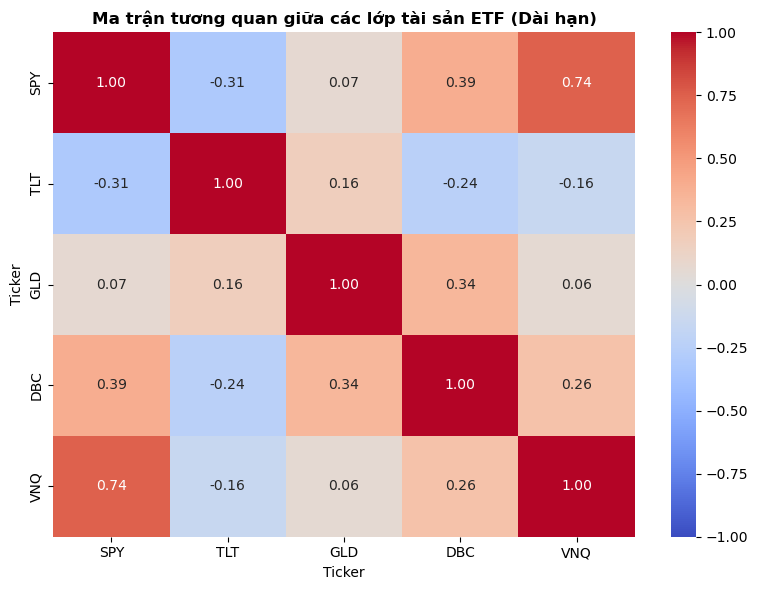


--- TRỌNG SỐ DANH MỤC RISK PARITY (DÀI HẠN) ---
- SPY: 19.80%
- TLT: 25.77%
- GLD: 21.21%
- DBC: 20.04%
- VNQ: 13.17%


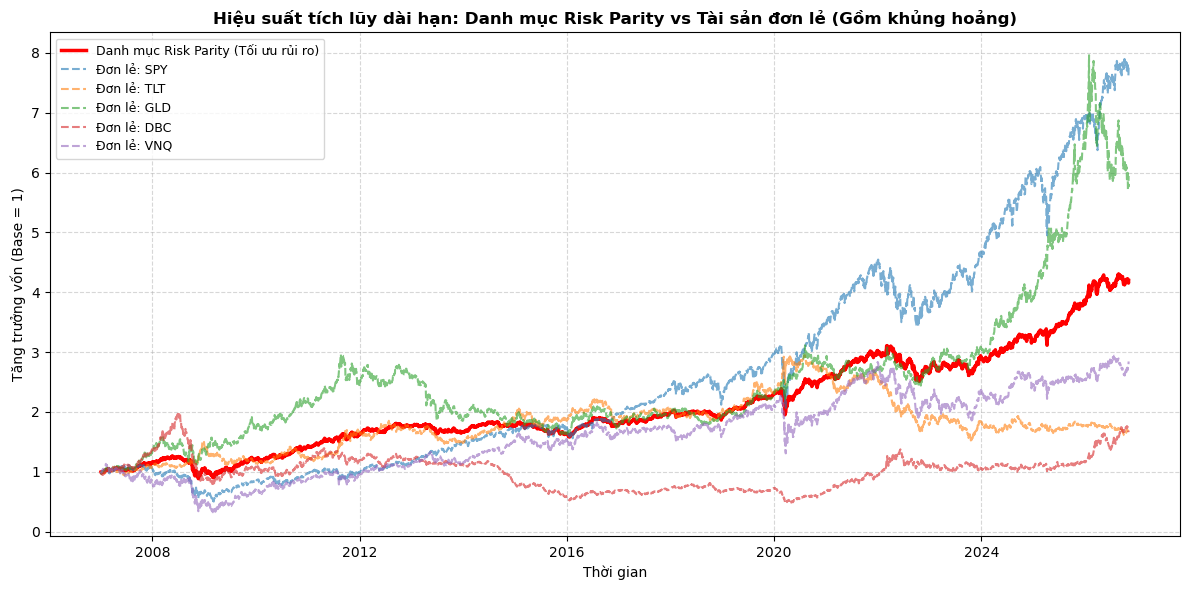

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# 1. Định nghĩa rổ ETF đại diện cho các lớp tài sản phi tương quan
# SPY: Cổ phiếu Mỹ, TLT: Trái phiếu dài hạn, GLD: Vàng, DBC: Hàng hóa, VNQ: Bất động sản
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]

print(
    "Đang tải dữ liệu lịch sử các ETF từ năm 2007 để kiểm chứng giai đoạn khủng"
    " hoảng..."
)
# Mở rộng thời gian bắt đầu từ 2007 để bao gồm khủng hoảng 2008 và COVID-19 2020
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)


# Lấy dữ liệu giá đóng cửa (Close)
def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()

# 2. Tính tỷ suất sinh lợi hàng ngày (Daily Returns)
returns = prices.pct_change().dropna()

# 3. Tính và hiển thị Ma trận tương quan (Correlation Matrix)
corr_matrix = returns.corr()
print("\n--- MA TRẬN TƯƠNG QUAN GIỮA CÁC TÀI SẢN (2007 - NAY) ---")
print(corr_matrix)

# Vẽ biểu đồ nhiệt (Heatmap) ma trận tương quan
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title(
    "Ma trận tương quan giữa các lớp tài sản ETF (Dài hạn)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# 4. Tính toán phân bổ Risk-Parity cơ bản (Inverse Volatility Weighting)
# Trọng số tỷ lệ nghịch với độ biến động (Standard Deviation) của từng tài sản
volatilities = returns.std()
inv_vol = 1.0 / volatilities
risk_parity_weights = inv_vol / np.sum(inv_vol)

print("\n--- TRỌNG SỐ DANH MỤC RISK PARITY (DÀI HẠN) ---")
for ticker, weight in risk_parity_weights.items():
  print(f"- {ticker}: {weight*100:.2f}%")

# 5. Kiểm tra hiệu suất danh mục so với từng tài sản đơn lẻ qua các thời kỳ sụp đổ
portfolio_returns = (returns * risk_parity_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục Risk Parity (Tối ưu rủi ro)",
    color="red",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.6,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy dài hạn: Danh mục Risk Parity vs Tài sản đơn lẻ (Gồm"
    " khủng hoảng)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [3]:
import os
import platform
import subprocess
import numpy as np
import openpyxl
import pandas as pd
import yfinance as yf
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# 1. Tải dữ liệu lịch sử các ETF từ năm 2007 đến nay
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print(
    "Đang tải dữ liệu lịch sử các ETF từ 2007 (bao gồm các chu kỳ khủng"
    " hoảng)..."
)
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()
returns = prices.pct_change().dropna()

# 2. Tính toán phân bổ Risk Parity (Inverse Volatility)
volatilities = returns.std()
inv_vol = 1.0 / volatilities
risk_parity_weights = inv_vol / np.sum(inv_vol)

portfolio_returns = (returns * risk_parity_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + returns).cumprod()

# 3. Tính toán các chỉ số thống kê hiệu suất
summary_data = []
for t in tickers + ["Risk_Parity_Portfolio"]:
  if t == "Risk_Parity_Portfolio":
    r = portfolio_returns
    cum = cumulative_portfolio
    w_val = "100.00%"
    name_label = "Danh mục Risk Parity"
  else:
    r = returns[t]
    cum = cumulative_assets[t]
    w_val = f"{risk_parity_weights[t]*100:.2f}%"
    name_label = f"{t} (Đơn lẻ)"

  total_return = cum.iloc[-1] - 1
  ann_return = (cum.iloc[-1]) ** (252 / len(cum)) - 1
  ann_vol = r.std() * np.sqrt(252)
  sharpe = ann_return / ann_vol if ann_vol != 0 else 0
  max_dd = (cum / cum.cummax() - 1).min()

  summary_data.append({
      "Tài sản / Danh mục": name_label,
      "Tỷ trọng (Weight)": w_val,
      "Tổng lợi nhuận": total_return,
      "Lợi nhuận năm (Ann. Return)": ann_return,
      "Độ biến động năm (Ann. Volatility)": ann_vol,
      "Sharpe Ratio": sharpe,
      "Mức sụt giảm tối đa (Max Drawdown)": max_dd,
  })

df_summary = pd.DataFrame(summary_data)
corr_matrix = returns.corr()

# 4. Tạo và định dạng File Excel bằng OpenPyXL
file_name = "ETF_Risk_Parity_Comparison.xlsx"
wb = openpyxl.Workbook()

# --- Sheet 1: Summary & Performance ---
ws_summary = wb.active
ws_summary.title = "Summary & Performance"

header_fill = PatternFill(
    start_color="1F497D", end_color="1F497D", fill_type="solid"
)
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=14, bold=True, color="1F497D")
bold_font = Font(name="Calibri", size=11, bold=True)
regular_font = Font(name="Calibri", size=11)
highlight_fill = PatternFill(
    start_color="DCE6F1", end_color="DCE6F1", fill_type="solid"
)
border_thin = Border(
    left=Side(style="thin", color="D9D9D9"),
    right=Side(style="thin", color="D9D9D9"),
    top=Side(style="thin", color="D9D9D9"),
    bottom=Side(style="thin", color="D9D9D9"),
)

ws_summary["A1"] = (
    "BẢNG SO SÁNH HIỆU SUẤT ĐẦU TƯ: TÀI SẢN ĐƠN LẺ VS DANH MỤC RISK PARITY"
)
ws_summary["A1"].font = title_font

headers = list(df_summary.columns)
for col_idx, h in enumerate(headers, 1):
  cell = ws_summary.cell(row=3, column=col_idx, value=h)
  cell.fill = header_fill
  cell.font = header_font
  cell.alignment = Alignment(
      horizontal="center", vertical="center", wrap_text=True
  )

for row_idx, row_data in enumerate(df_summary.values, 4):
  is_portfolio = row_idx == 4 + len(df_summary) - 1
  for col_idx, val in enumerate(row_data, 1):
    cell = ws_summary.cell(row=row_idx, column=col_idx, value=val)
    cell.font = bold_font if is_portfolio else regular_font
    cell.border = border_thin
    if is_portfolio:
      cell.fill = highlight_fill

    # Định dạng hiển thị số/phần trăm
    if col_idx == 1:
      cell.alignment = Alignment(horizontal="left")
    elif col_idx == 2:
      cell.alignment = Alignment(horizontal="right")
    elif col_idx in [3, 4, 5, 7]:
      cell.number_format = "0.00%"
      cell.alignment = Alignment(horizontal="right")
    elif col_idx == 6:
      cell.number_format = "0.00"
      cell.alignment = Alignment(horizontal="right")

for col in ws_summary.columns:
  max_len = max(len(str(cell.value or "")) for cell in col)
  col_letter = get_column_letter(col[0].column)
  ws_summary.column_dimensions[col_letter].width = max(max_len + 4, 15)

# --- Sheet 2: Correlation Matrix ---
ws_corr = wb.create_sheet(title="Correlation Matrix")
ws_corr["A1"] = "MA TRẬN TƯƠNG QUAN LỊCH SỬ (2007 - NAY)"
ws_corr["A1"].font = title_font

corr_headers = [""] + list(corr_matrix.columns)
for col_idx, h in enumerate(corr_headers, 1):
  cell = ws_corr.cell(row=3, column=col_idx, value=h)
  if col_idx > 1:
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center")

for row_idx, (idx_name, row_data) in enumerate(
    zip(corr_matrix.index, corr_matrix.values), 4
):
  cell_idx = ws_corr.cell(row=row_idx, column=1, value=idx_name)
  cell_idx.font = bold_font
  cell_idx.border = border_thin
  for col_idx, val in enumerate(row_data, 2):
    cell = ws_corr.cell(row=row_idx, column=col_idx, value=val)
    cell.font = regular_font
    cell.border = border_thin
    cell.number_format = "0.0000"
    cell.alignment = Alignment(horizontal="right")

wb.save(file_name)
print(f"File Excel đã được lưu thành công tại: {os.path.abspath(file_name)}")

# 5. Tự động mở File Excel bằng OS
file_path = os.path.abspath(file_name)
try:
  if platform.system() == "Darwin":  # macOS
    subprocess.run(["open", file_path])
  elif platform.system() == "Windows":  # Windows
    os.startfile(file_path)
  else:  # Linux
    subprocess.run(["xdg-open", file_path])
  print("Đã thực thi lệnh mở file Excel trước màn hình.")
except Exception as e:
  print(f"Không thể tự động mở file: {e}")

Đang tải dữ liệu lịch sử các ETF từ 2007 (bao gồm các chu kỳ khủng hoảng)...


[*********************100%***********************]  5 of 5 completed


File Excel đã được lưu thành công tại: C:\Users\LocalUserName\Desktop\sci\science\ETF_Risk_Parity_Comparison.xlsx
Đã thực thi lệnh mở file Excel trước màn hình.


Đang tải dữ liệu lịch sử các ETF từ năm 2007...


[*********************100%***********************]  5 of 5 completed


Đang quét tìm bậc vi phân d tối ưu cho SPY...
-> Tìm thấy d tối ưu = 0.7 (ADF p-value: 0.0026 < 0.05)

--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---
-> Precision (Độ chính xác lọc lệnh): 54.62%
-> Recall (Tỷ lệ bao phủ tín hiệu): 3.05%

--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---
- DBC: 58.66%
- GLD: 8.38%
- SPY: 8.38%
- TLT: 14.26%
- VNQ: 10.31%


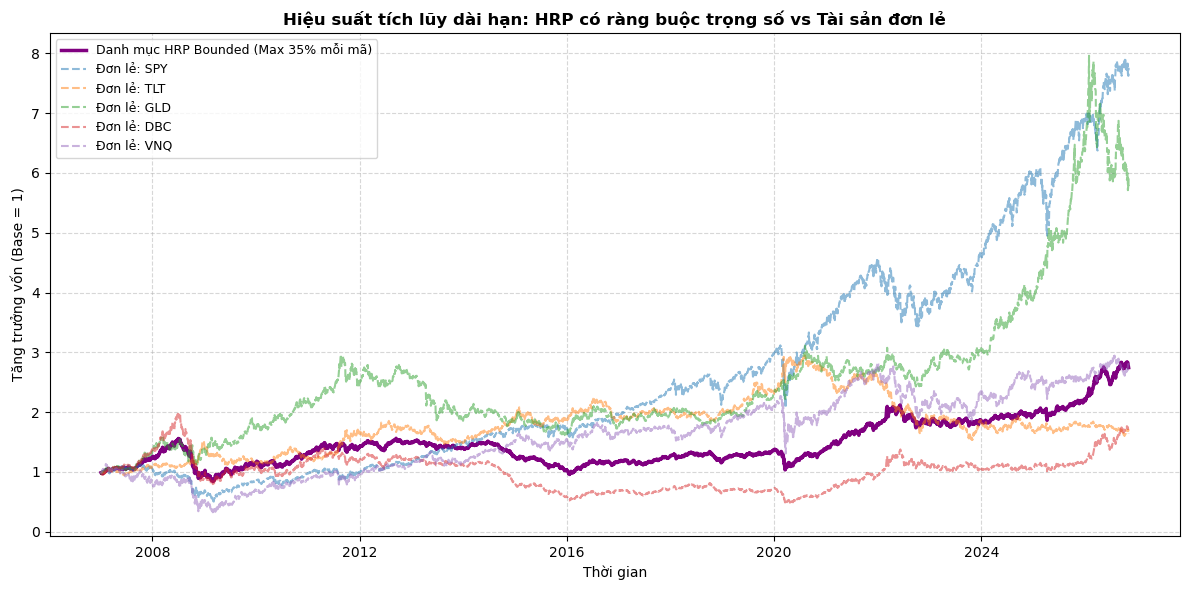

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf
from arch.unitroot import ADF
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU LỊCH SỬ TỪ NĂM 2007
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF từ năm 2007...")
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ & TÌM d TỐI ƯU (ADF Test)
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("Đang quét tìm bậc vi phân d tối ưu cho SPY...")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: MÔ HÌNH SƠ CẤP & META-LABELING (TRIPLE-BARRIER)
# =====================================================================
short_ma = prices["SPY"].rolling(window=10).mean()
long_ma = prices["SPY"].rolling(window=50).mean()
primary_side = pd.Series(index=prices.index, data=0)
primary_side[short_ma > long_ma] = 1
primary_side[short_ma <= long_ma] = -1
primary_side = primary_side.dropna()


def get_meta_labels(prices_series, sides, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=sides.index)
  events["vol"] = vol
  events["side"] = sides

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]

  meta_labels = pd.Series(index=events.index, dtype=float)
  for loc, t1 in events["t1"].items():
    side = events.loc[loc, "side"]
    if side == 0:
      continue
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * side
    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index
    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      meta_labels.loc[loc] = 1
    else:
      meta_labels.loc[loc] = 0
  return meta_labels.dropna()


meta_y = get_meta_labels(prices["SPY"], primary_side)


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG & PURGED CROSS-VALIDATION
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)
common_idx = features_df.index.intersection(meta_y.index)
X = features_df.loc[common_idx]
y = meta_y.loc[common_idx]


class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---")
optimal_threshold = 0.60
all_y_true, all_preds_thresh = [], []

pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)
for train_idx, test_idx in pkf.split(X):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  meta_classifier = RandomForestClassifier(
      n_estimators=100, max_depth=4, random_state=42, class_weight="balanced"
  )
  meta_classifier.fit(X_train, y_train)

  probs = meta_classifier.predict_proba(X_test)[:, 1]
  preds_thresh = (probs >= optimal_threshold).astype(int)

  all_y_true.extend(y_test.values)
  all_preds_thresh.extend(preds_thresh)

final_prec = precision_score(all_y_true, all_preds_thresh, zero_division=0)
final_rec = recall_score(all_y_true, all_preds_thresh, zero_division=0)
print(f"-> Precision (Độ chính xác lọc lệnh): {final_prec*100:.2f}%")
print(f"-> Recall (Tỷ lệ bao phủ tín hiệu): {final_rec*100:.2f}%")


# =====================================================================
# BƯỚC 5: HIERARCHICAL RISK PARITY (HRP) CÓ RÀNG BUỘC TỶ TRỌNG
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp_bounded(
    returns, max_weight=0.35, min_weight=0.05
):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()

  w = get_rec_bisection(cov, sort_ix).sort_index()

  # Ràng buộc tỷ trọng: Capping tối đa và tối thiểu, sau đó chuẩn hóa tổng = 1.0
  w = w.clip(lower=min_weight, upper=max_weight)
  w = w / w.sum()
  return w


hrp_weights = optimal_portfolio_hrp_bounded(
    diff_prices, max_weight=0.35, min_weight=0.05
)

print("\n--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")


# =====================================================================
# BƯỚC 6: BACKTEST VÀ VẼ BIỂU ĐỒ SO SÁNH HIỆU SUẤT
# =====================================================================
raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP Bounded (Max 35% mỗi mã)",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy dài hạn: HRP có ràng buộc trọng số vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF từ năm 2007...


[*********************100%***********************]  5 of 5 completed


Đang quét tìm bậc vi phân d tối ưu cho SPY...
-> Tìm thấy d tối ưu = 0.7 (ADF p-value: 0.0027 < 0.05)

--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---
-> Precision (Độ chính xác lọc lệnh): 54.78%
-> Recall (Tỷ lệ bao phủ tín hiệu): 2.96%

--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---
- DBC: 35.00%
- GLD: 13.18%
- SPY: 13.18%
- TLT: 22.43%
- VNQ: 16.22%


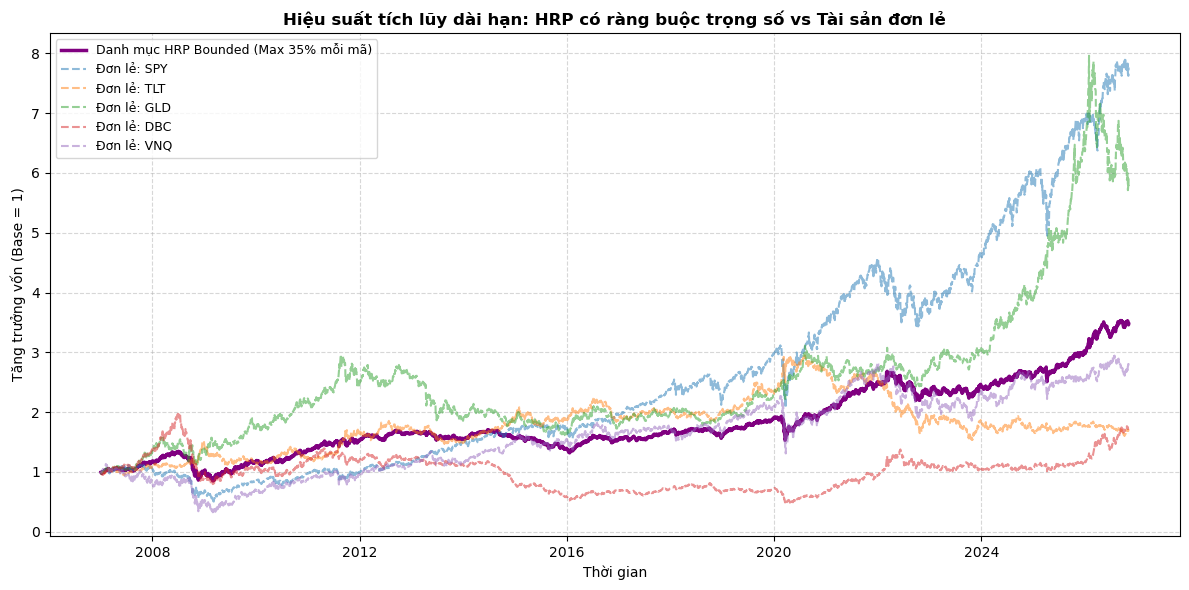

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf
from arch.unitroot import ADF
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU LỊCH SỬ TỪ NĂM 2007
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF từ năm 2007...")
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ & TÌM d TỐI ƯU (ADF Test)
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("Đang quét tìm bậc vi phân d tối ưu cho SPY...")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: MÔ HÌNH SƠ CẤP & META-LABELING (TRIPLE-BARRIER)
# =====================================================================
short_ma = prices["SPY"].rolling(window=10).mean()
long_ma = prices["SPY"].rolling(window=50).mean()
primary_side = pd.Series(index=prices.index, data=0)
primary_side[short_ma > long_ma] = 1
primary_side[short_ma <= long_ma] = -1
primary_side = primary_side.dropna()


def get_meta_labels(prices_series, sides, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=sides.index)
  events["vol"] = vol
  events["side"] = sides

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]

  meta_labels = pd.Series(index=events.index, dtype=float)
  for loc, t1 in events["t1"].items():
    side = events.loc[loc, "side"]
    if side == 0:
      continue
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * side
    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index
    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      meta_labels.loc[loc] = 1
    else:
      meta_labels.loc[loc] = 0
  return meta_labels.dropna()


meta_y = get_meta_labels(prices["SPY"], primary_side)


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG & PURGED CROSS-VALIDATION
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)
common_idx = features_df.index.intersection(meta_y.index)
X = features_df.loc[common_idx]
y = meta_y.loc[common_idx]


class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---")
optimal_threshold = 0.60
all_y_true, all_preds_thresh = [], []

pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)
for train_idx, test_idx in pkf.split(X):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  meta_classifier = RandomForestClassifier(
      n_estimators=100, max_depth=4, random_state=42, class_weight="balanced"
  )
  meta_classifier.fit(X_train, y_train)

  probs = meta_classifier.predict_proba(X_test)[:, 1]
  preds_thresh = (probs >= optimal_threshold).astype(int)

  all_y_true.extend(y_test.values)
  all_preds_thresh.extend(preds_thresh)

final_prec = precision_score(all_y_true, all_preds_thresh, zero_division=0)
final_rec = recall_score(all_y_true, all_preds_thresh, zero_division=0)
print(f"-> Precision (Độ chính xác lọc lệnh): {final_prec*100:.2f}%")
print(f"-> Recall (Tỷ lệ bao phủ tín hiệu): {final_rec*100:.2f}%")


# =====================================================================
# BƯỚC 5: HIERARCHICAL RISK PARITY (HRP) CÓ RÀNG BUỘC TỶ TRỌNG (ITERATIVE)
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp_bounded(
    returns, max_weight=0.35, min_weight=0.05, max_iter=100
):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()

  w = get_rec_bisection(cov, sort_ix).sort_index()

  # Thuật toán lặp chuẩn hóa để ép chặt min/max chính xác tuyệt đối
  for _ in range(max_iter):
    w = w.clip(lower=min_weight, upper=max_weight)
    if np.isclose(w.sum(), 1.0):
      break
    w = w / w.sum()
  return w


hrp_weights = optimal_portfolio_hrp_bounded(
    diff_prices, max_weight=0.35, min_weight=0.05
)

print("\n--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")


# =====================================================================
# BƯỚC 6: BACKTEST VÀ VẼ BIỂU ĐỒ SO SÁNH HIỆU SUẤT
# =====================================================================
raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP Bounded (Max 35% mỗi mã)",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy dài hạn: HRP có ràng buộc trọng số vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử các ETF từ năm 2007...


[*********************100%***********************]  5 of 5 completed


Đang quét tìm bậc vi phân d tối ưu cho SPY...
-> Tìm thấy d tối ưu = 0.7 (ADF p-value: 0.0027 < 0.05)

--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---
-> Precision (Độ chính xác lọc lệnh): 51.69%
-> Recall (Tỷ lệ bao phủ tín hiệu): 2.87%

--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---
- DBC: 35.00%
- GLD: 13.18%
- SPY: 13.18%
- TLT: 22.43%
- VNQ: 16.22%

File Excel đã tạo tại: C:\Users\LocalUserName\Desktop\sci\science\Quant_HRP_Bounded_Backtest.xlsx


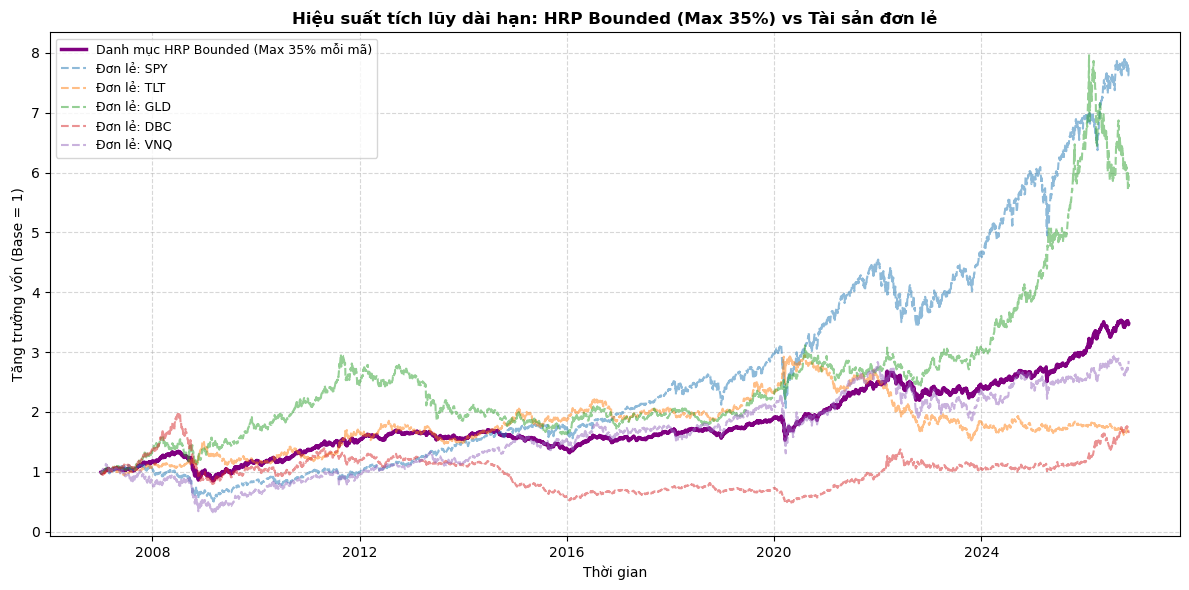

In [9]:
import os
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import scipy.cluster.hierarchy as sch
import yfinance as yf
from arch.unitroot import ADF
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

# =====================================================================
# BƯỚC 1: TẢI DỮ LIỆU LỊCH SỬ TỪ NĂM 2007
# =====================================================================
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
print("Đang tải dữ liệu lịch sử các ETF từ năm 2007...")
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)


def get_close_prices(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"]
  return df


prices = get_close_prices(data)[tickers].dropna()


# =====================================================================
# BƯỚC 2: VI PHÂN PHÂN SỐ & TÌM d TỐI ƯU (ADF Test)
# =====================================================================
def get_weights(d, size):
  w = [1.0]
  for k in range(1, size):
    w.append(-w[-1] / k * (d - k + 1))
  return np.array(w[::-1])


def fractional_differencing(series, d=0.4, threshold=1e-4):
  weights = get_weights(d, len(series))
  drop_weights = np.where(np.abs(weights) < threshold)[0]
  if len(drop_weights) > 0:
    weights = weights[drop_weights[-1] + 1 :]
  res = []
  for i in range(len(weights), len(series) + 1):
    val = np.dot(weights, series.iloc[i - len(weights) : i])
    res.append(val)
  return pd.Series(
      res, index=series.index[len(series) - len(res) :], name=series.name
  )


print("Đang quét tìm bậc vi phân d tối ưu cho SPY...")
optimal_d = 0.4
for d_test in np.arange(0.1, 1.0, 0.1):
  diff_series = fractional_differencing(prices["SPY"], d=d_test).dropna()
  adf_res = ADF(diff_series)
  if adf_res.pvalue < 0.05:
    optimal_d = round(d_test, 2)
    print(
        f"-> Tìm thấy d tối ưu = {optimal_d} (ADF p-value:"
        f" {adf_res.pvalue:.4f} < 0.05)"
    )
    break

diff_prices = pd.DataFrame(
    {col: fractional_differencing(prices[col], d=optimal_d) for col in tickers}
).dropna()


# =====================================================================
# BƯỚC 3: MÔ HÌNH SƠ CẤP & META-LABELING (TRIPLE-BARRIER)
# =====================================================================
short_ma = prices["SPY"].rolling(window=10).mean()
long_ma = prices["SPY"].rolling(window=50).mean()
primary_side = pd.Series(index=prices.index, data=0)
primary_side[short_ma > long_ma] = 1
primary_side[short_ma <= long_ma] = -1
primary_side = primary_side.dropna()


def get_meta_labels(prices_series, sides, pt_sl=[1, 1], span=50, horizon=5):
  vol = prices_series.pct_change().ewm(span=span).std()
  events = pd.DataFrame(index=sides.index)
  events["vol"] = vol
  events["side"] = sides

  max_idx = len(prices_series) - 1
  t1_indices = [min(max_idx, i + horizon) for i in range(len(prices_series))]
  events["t1"] = prices_series.index[t1_indices]

  meta_labels = pd.Series(index=events.index, dtype=float)
  for loc, t1 in events["t1"].items():
    side = events.loc[loc, "side"]
    if side == 0:
      continue
    df0 = prices_series.loc[loc:t1]
    if len(df0) <= 1:
      continue
    ret = (df0 / prices_series.loc[loc] - 1) * side
    current_vol = events.loc[loc, "vol"]
    if pd.isna(current_vol) or current_vol == 0:
      continue

    hit_sl = ret[ret < -pt_sl[1] * current_vol].index
    hit_pt = ret[ret > pt_sl[0] * current_vol].index
    first_hit = pd.Series(
        [
            hit_sl.min() if len(hit_sl) > 0 else pd.NaT,
            hit_pt.min() if len(hit_pt) > 0 else pd.NaT,
        ],
        index=["sl", "pt"],
    ).min()

    if first_hit in hit_pt and first_hit not in hit_sl:
      meta_labels.loc[loc] = 1
    else:
      meta_labels.loc[loc] = 0
  return meta_labels.dropna()


meta_y = get_meta_labels(prices["SPY"], primary_side)


# =====================================================================
# BƯỚC 4: TRÍCH XUẤT ĐẶC TRƯNG & PURGED CROSS-VALIDATION
# =====================================================================
def extract_features(df_prices):
  features = pd.DataFrame(index=df_prices.index)
  for col in df_prices.columns:
    features[f"{col}_ma_ratio"] = df_prices[col] / df_prices[col].rolling(20).mean()
    features[f"{col}_vol"] = df_prices[col].pct_change().rolling(20).std()
  return features.dropna()


features_df = extract_features(diff_prices)
common_idx = features_df.index.intersection(meta_y.index)
X = features_df.loc[common_idx]
y = meta_y.loc[common_idx]


class PurgedKFold:

  def __init__(self, n_splits=5, embargo_pct=0.01):
    self.n_splits = n_splits
    self.embargo_pct = embargo_pct

  def split(self, X):
    indices = np.arange(X.shape[0])
    n = len(indices)
    test_pts = np.array_split(np.arange(n), self.n_splits)
    for test_idx in test_pts:
      test_start, test_end = indices[test_idx[0]], indices[test_idx[-1]]
      train_idx = np.setdiff1d(np.arange(n), test_idx)
      embargo_idx = int(n * self.embargo_pct)
      if embargo_idx > 0:
        train_idx = train_idx[
            (train_idx < test_start) | (train_idx > test_end + embargo_idx)
        ]
      yield train_idx, test_idx


print("\n--- ĐÁNH GIÁ META-MODEL VỚI PROBABILITY THRESHOLDING (>= 0.60) ---")
optimal_threshold = 0.60
all_y_true, all_preds_thresh = [], []

pkf = PurgedKFold(n_splits=5, embargo_pct=0.01)
for train_idx, test_idx in pkf.split(X):
  X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
  X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

  meta_classifier = RandomForestClassifier(
      n_estimators=100, max_depth=4, random_state=42, class_weight="balanced"
  )
  meta_classifier.fit(X_train, y_train)

  probs = meta_classifier.predict_proba(X_test)[:, 1]
  preds_thresh = (probs >= optimal_threshold).astype(int)

  all_y_true.extend(y_test.values)
  all_preds_thresh.extend(preds_thresh)

final_prec = precision_score(all_y_true, all_preds_thresh, zero_division=0)
final_rec = recall_score(all_y_true, all_preds_thresh, zero_division=0)
print(f"-> Precision (Độ chính xác lọc lệnh): {final_prec*100:.2f}%")
print(f"-> Recall (Tỷ lệ bao phủ tín hiệu): {final_rec*100:.2f}%")


# =====================================================================
# BƯỚC 5: HIERARCHICAL RISK PARITY (HRP) CÓ RÀNG BUỘC TỶ TRỌNG (ITERATIVE)
# =====================================================================
def get_quasi_diag(link):
  link = link.astype(int)
  sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
  num_items = link[-1, 3]
  while sort_ix.max() >= num_items:
    sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
    df0 = sort_ix[sort_ix >= num_items]
    i = df0.index
    j = df0.values
    sort_ix[i] = link[j - num_items, 0]
    df1 = pd.Series(link[j - num_items, 1], index=i + 1)
    sort_ix = pd.concat([sort_ix, df1]).sort_index()
    sort_ix.index = range(sort_ix.shape[0])
  return sort_ix.tolist()


def get_cluster_var(cov, cluster_items):
  cov_slice = cov.loc[cluster_items, cluster_items]
  w = 1.0 / np.diag(cov_slice)
  w /= w.sum()
  return np.dot(w.T, np.dot(cov_slice, w))


def get_rec_bisection(cov, sort_ix):
  w = pd.Series(1.0, index=sort_ix)
  clustered_weights = [sort_ix]
  while len(clustered_weights) > 0:
    clustered_weights = [
        i[j:k]
        for i in clustered_weights
        for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
        if len(i) > 1
    ]
    for i in range(0, len(clustered_weights), 2):
      cluster1 = clustered_weights[i]
      cluster2 = clustered_weights[i + 1]
      c1_var = get_cluster_var(cov, cluster1)
      c2_var = get_cluster_var(cov, cluster2)
      alpha = 1 - c1_var / (c1_var + c2_var)
      w[cluster1] *= alpha
      w[cluster2] *= 1 - alpha
  return w


def optimal_portfolio_hrp_bounded(
    returns, max_weight=0.35, min_weight=0.05, max_iter=100
):
  corr = returns.corr()
  cov = returns.cov()
  dist = np.sqrt((1 - corr) / 2.0)
  link = sch.linkage(sch.distance.pdist(dist), method="single")
  sort_ix = get_quasi_diag(link)
  sort_ix = corr.index[sort_ix].tolist()

  w = get_rec_bisection(cov, sort_ix).sort_index()

  for _ in range(max_iter):
    w = w.clip(lower=min_weight, upper=max_weight)
    if np.isclose(w.sum(), 1.0):
      break
    w = w / w.sum()
  return w


hrp_weights = optimal_portfolio_hrp_bounded(
    diff_prices, max_weight=0.35, min_weight=0.05
)

print("\n--- TRỌNG SỐ DANH MỤC HRP CÓ RÀNG BUỘC (MAX 35%) ---")
for ticker, weight in hrp_weights.items():
  print(f"- {ticker}: {weight * 100:.2f}%")

# =====================================================================
# BƯỚC 6: TRÍCH XUẤT EXCEL & VẼ BIỂU ĐỒ SO SÁNH
# =====================================================================
raw_returns = prices.pct_change().dropna()
portfolio_returns = (raw_returns * hrp_weights).sum(axis=1)
cumulative_portfolio = (1 + portfolio_returns).cumprod()
cumulative_assets = (1 + raw_returns).cumprod()

wb = openpyxl.Workbook()
ws_summary = wb.active
ws_summary.title = "Summary & Metrics"

header_fill = PatternFill(
    start_color="1F497D", end_color="1F497D", fill_type="solid"
)
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=14, bold=True, color="1F497D")
bold_font = Font(name="Calibri", size=11, bold=True)
regular_font = Font(name="Calibri", size=11)
highlight_fill = PatternFill(
    start_color="DCE6F1", end_color="DCE6F1", fill_type="solid"
)
border_thin = Border(
    left=Side(style="thin", color="D9D9D9"),
    right=Side(style="thin", color="D9D9D9"),
    top=Side(style="thin", color="D9D9D9"),
    bottom=Side(style="thin", color="D9D9D9"),
)

ws_summary["A1"] = (
    "BẢNG TỔNG HỢP HIỆU SUẤT DANH MỤC HRP CÓ RÀNG BUỘC (BOUNDED MAX 35%)"
)
ws_summary["A1"].font = title_font

headers_summary = [
    "Tài sản / Danh mục",
    "Tỷ trọng HRP (Weight)",
    "Tổng lợi nhuận (Total Return)",
    "Lợi nhuận năm (Ann. Return)",
    "Độ biến động năm (Ann. Volatility)",
    "Sharpe Ratio",
    "Mức sụt giảm tối đa (Max Drawdown)",
]

for col_idx, h in enumerate(headers_summary, 1):
  cell = ws_summary.cell(row=3, column=col_idx, value=h)
  cell.fill = header_fill
  cell.font = header_font
  cell.alignment = Alignment(
      horizontal="center", vertical="center", wrap_text=True
  )

summary_rows = []
for t in tickers + ["HRP_Portfolio"]:
  if t == "HRP_Portfolio":
    r = portfolio_returns
    cum = cumulative_portfolio
    w_val = 1.0
    name_label = "Danh mục HRP Bounded (Max 35%)"
  else:
    r = raw_returns[t]
    cum = cumulative_assets[t]
    w_val = hrp_weights[t]
    name_label = f"{t} (Đơn lẻ)"

  tot_ret = cum.iloc[-1] - 1
  ann_ret = (cum.iloc[-1]) ** (252 / len(cum)) - 1
  ann_vol = r.std() * np.sqrt(252)
  sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
  max_dd = (cum / cum.cummax() - 1).min()

  summary_rows.append(
      [name_label, w_val, tot_ret, ann_ret, ann_vol, sharpe, max_dd]
  )

for row_idx, row_data in enumerate(summary_rows, 4):
  is_portfolio = row_idx == 4 + len(summary_rows) - 1
  for col_idx, val in enumerate(row_data, 1):
    cell = ws_summary.cell(row=row_idx, column=col_idx, value=val)
    cell.font = bold_font if is_portfolio else regular_font
    cell.border = border_thin
    if is_portfolio:
      cell.fill = highlight_fill

    if col_idx == 1:
      cell.alignment = Alignment(horizontal="left")
    elif col_idx in [2, 3, 4, 5, 7]:
      cell.number_format = "0.00%"
      cell.alignment = Alignment(horizontal="right")
    elif col_idx == 6:
      cell.number_format = "0.00"
      cell.alignment = Alignment(horizontal="right")

for col in ws_summary.columns:
  max_len = max(len(str(cell.value or "")) for cell in col)
  col_letter = get_column_letter(col[0].column)
  ws_summary.column_dimensions[col_letter].width = max(max_len + 4, 16)

file_excel = "Quant_HRP_Bounded_Backtest.xlsx"
wb.save(file_excel)
print(f"\nFile Excel đã tạo tại: {os.path.abspath(file_excel)}")

# Biểu đồ Backtest
plt.figure(figsize=(12, 6))
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    label="Danh mục HRP Bounded (Max 35% mỗi mã)",
    color="purple",
    linewidth=2.5,
)
for ticker in tickers:
  plt.plot(
      cumulative_assets.index,
      cumulative_assets[ticker],
      linestyle="--",
      alpha=0.5,
      label=f"Đơn lẻ: {ticker}",
  )

plt.title(
    "Hiệu suất tích lũy dài hạn: HRP Bounded (Max 35%) vs Tài sản đơn lẻ",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Thời gian", fontsize=10)
plt.ylabel("Tăng trưởng vốn (Base = 1)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [10]:
import os
import openpyxl
import pandas as pd
import yfinance as yf
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# 1. Danh sách ETF
tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]

print("Đang tải dữ liệu lịch sử các ETF từ yfinance...")
data = yf.download(tickers, start="2007-01-01", interval="1d", auto_adjust=True)

# Lấy giá đóng cửa Close
if isinstance(data.columns, pd.MultiIndex):
  prices = data["Close"]
else:
  prices = data

prices = prices[tickers].dropna()

# 2. Resample sang dữ liệu giá theo tháng (Monthly Price - Lấy ngày giao dịch cuối cùng của tháng)
monthly_prices = prices.resample("ME").last().dropna()

# 3. Khởi tạo Workbook Excel với định dạng đẹp mắt
wb = openpyxl.Workbook()
wb.remove(wb.active)  # Xóa sheet mặc định

title_font = Font(name="Calibri", size=14, bold=True, color="1F497D")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
header_fill = PatternFill(
    start_color="1F497D", end_color="1F497D", fill_type="solid"
)
bold_font = Font(name="Calibri", size=11, bold=True)
regular_font = Font(name="Calibri", size=11)
border_thin = Border(
    left=Side(style="thin", color="D9D9D9"),
    right=Side(style="thin", color="D9D9D9"),
    top=Side(style="thin", color="D9D9D9"),
    bottom=Side(style="thin", color="D9D9D9"),
)

# 4. Sheet 1: Tổng hợp giá theo tháng của tất cả các Asset
ws_all = wb.create_sheet(title="All Assets Monthly")
ws_all["A1"] = "BẢNG TỔNG HỢP GIÁ ĐÓNG CỬA HÀNG THÁNG (2007 - NAY)"
ws_all["A1"].font = title_font

headers_all = ["Ngày (Date)"] + tickers
for col_idx, h in enumerate(headers_all, 1):
  cell = ws_all.cell(row=3, column=col_idx, value=h)
  cell.fill = header_fill
  cell.font = header_font
  cell.alignment = Alignment(horizontal="center", vertical="center")

for row_idx, (date_val, row_data) in enumerate(
    zip(monthly_prices.index, monthly_prices.values), 4
):
  cell_date = ws_all.cell(
      row=row_idx, column=1, value=date_val.strftime("%Y-%m-%d")
  )
  cell_date.font = regular_font
  cell_date.border = border_thin
  cell_date.alignment = Alignment(horizontal="center")

  for col_idx, price in enumerate(row_data, 2):
    cell = ws_all.cell(row=row_idx, column=col_idx, value=price)
    cell.font = regular_font
    cell.border = border_thin
    cell.number_format = "$#,##0.00"
    cell.alignment = Alignment(horizontal="right")

for col in ws_all.columns:
  max_len = max(len(str(cell.value or "")) for cell in col)
  col_letter = get_column_letter(col[0].column)
  ws_all.column_dimensions[col_letter].width = max(max_len + 4, 15)

# 5. Sheet 2 -> 6: Sheet riêng biệt cho từng mã ETF (Monthly Price & Monthly Return)
ticker_names = {
    "SPY": "SPDR S&P 500 ETF Trust",
    "TLT": "iShares 20+ Year Treasury Bond ETF",
    "GLD": "SPDR Gold Shares",
    "DBC": "Invesco DB Commodity Index Tracking Fund",
    "VNQ": "Vanguard Real Estate ETF",
}

for ticker in tickers:
  ws = wb.create_sheet(title=f"Monthly {ticker}")
  ws["A1"] = (
      f"DỮ LIỆU GIÁ HÀNG THÁNG & LỢI NHUẬN: {ticker} ({ticker_names[ticker]})"
  )
  ws["A1"].font = title_font

  headers = [
      "Ngày (Date)",
      f"Giá đóng cửa ({ticker})",
      "Lợi nhuận tháng (Monthly Return)",
  ]
  for col_idx, h in enumerate(headers, 1):
    cell = ws.cell(row=3, column=col_idx, value=h)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center")

  s_price = monthly_prices[ticker]
  s_return = s_price.pct_change()

  for row_idx, date_val in enumerate(monthly_prices.index, 4):
    p_val = s_price.loc[date_val]
    r_val = s_return.loc[date_val]

    c_date = ws.cell(
        row=row_idx, column=1, value=date_val.strftime("%Y-%m-%d")
    )
    c_date.font = regular_font
    c_date.border = border_thin
    c_date.alignment = Alignment(horizontal="center")

    c_price = ws.cell(row=row_idx, column=2, value=p_val)
    c_price.font = regular_font
    c_price.border = border_thin
    c_price.number_format = "$#,##0.00"
    c_price.alignment = Alignment(horizontal="right")

    c_ret = ws.cell(
        row=row_idx, column=3, value=r_val if not pd.isna(r_val) else 0
    )
    c_ret.font = regular_font
    c_ret.border = border_thin
    c_ret.number_format = "0.00%"
    c_ret.alignment = Alignment(horizontal="right")

  for col in ws.columns:
    max_len = max(len(str(cell.value or "")) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 4, 20)

# 6. Lưu file Excel
file_name = "ETF_Monthly_Prices_By_Asset.xlsx"
wb.save(file_name)
print(f"Lưu thành công file Excel tại: {os.path.abspath(file_name)}")

Đang tải dữ liệu lịch sử các ETF từ yfinance...


[*********************100%***********************]  5 of 5 completed


Lưu thành công file Excel tại: C:\Users\LocalUserName\Desktop\sci\science\ETF_Monthly_Prices_By_Asset.xlsx


In [12]:
import openpyxl
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu giá từ file Excel lịch sử
file_path = "ETF_Monthly_Prices_By_Asset.xlsx"
df_all = pd.read_excel(file_path, sheet_name="All Assets Monthly", skiprows=2)
df_all.columns = ["Date", "SPY", "TLT", "GLD", "DBC", "VNQ"]
df_all["Date"] = pd.to_datetime(df_all["Date"])
df_all = df_all.set_index("Date")

tickers = ["SPY", "TLT", "GLD", "DBC", "VNQ"]
hrp_weights = pd.Series(
    {"DBC": 0.3500, "TLT": 0.2243, "VNQ": 0.1622, "GLD": 0.1318, "SPY": 0.1318}
)[tickers]
monthly_returns = df_all.pct_change().dropna()
port_returns = (monthly_returns * hrp_weights).sum(axis=1)

initial_capital = 100000.0  # Vốn giả lập 100,000 USD

# 2. Khởi tạo và thiết lập định dạng workbook Excel
wb = openpyxl.Workbook()
wb.remove(wb.active)

title_font = Font(name="Calibri", size=14, bold=True, color="1F497D")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
header_fill = PatternFill(
    start_color="1F497D", end_color="1F497D", fill_type="solid"
)
regular_font = Font(name="Calibri", size=11)
border_thin = Border(
    left=Side(style="thin", color="D9D9D9"),
    right=Side(style="thin", color="D9D9D9"),
    top=Side(style="thin", color="D9D9D9"),
    bottom=Side(style="thin", color="D9D9D9"),
)

# 3. Tạo Sheet 1: Nhật ký tái cân bằng hàng năm (Annual Rebalancing Log)
ws_annual = wb.create_sheet(title="Annual Rebalancing Log")
ws_annual["A1"] = (
    "LỊCH SỬ GIAO DỊCH TÁI CÂN BẰNG DANH MỤC HÀNG NĂM (ANNUAL REBALANCING)"
)
ws_annual["A1"].font = title_font

headers_annual = [
    "Ngày tái cân bằng",
    "Tổng giá trị danh mục ($)",
    "Mã ETF",
    "Tỷ trọng mục tiêu",
    "Giá trị phân bổ ($)",
    "Giá đóng cửa ($)",
    "Số lượng Cổ phiếu (Shares)",
]

for col_idx, h in enumerate(headers_annual, 1):
  cell = ws_annual.cell(row=3, column=col_idx, value=h)
  cell.fill = header_fill
  cell.font = header_font
  cell.alignment = Alignment(horizontal="center", vertical="center")

rebalance_dates = df_all.resample("Y").last().index
current_row = 4

for d in rebalance_dates:
  if d not in df_all.index:
    continue
  prices_at_d = df_all.loc[d]
  cum_ret = (1 + port_returns.loc[:d]).cumprod().iloc[-1]
  nav = initial_capital * cum_ret

  for t in tickers:
    w = hrp_weights[t]
    alloc_val = nav * w
    p = prices_at_d[t]
    shares = alloc_val / p

    ws_annual.cell(
        row=current_row, column=1, value=d.strftime("%Y-%m-%d")
    ).alignment = Alignment(horizontal="center")
    ws_annual.cell(row=current_row, column=2, value=nav).number_format = (
        "$#,##0.00"
    )
    ws_annual.cell(row=current_row, column=3, value=t).alignment = Alignment(
        horizontal="center"
    )
    ws_annual.cell(row=current_row, column=4, value=w).number_format = "0.00%"
    ws_annual.cell(row=current_row, column=5, value=alloc_val).number_format = (
        "$#,##0.00"
    )
    ws_annual.cell(row=current_row, column=6, value=p).number_format = "$#,##0.00"
    ws_annual.cell(row=current_row, column=7, value=shares).number_format = (
        "#,##0.00"
    )

    for c in range(1, 8):
      ws_annual.cell(row=current_row, column=c).border = border_thin
      ws_annual.cell(row=current_row, column=c).font = regular_font
    current_row += 1

for col in ws_annual.columns:
  max_len = max(len(str(cell.value or "")) for cell in col)
  col_letter = get_column_letter(col[0].column)
  ws_annual.column_dimensions[col_letter].width = max(max_len + 4, 18)

# 4. Tạo Sheet 2: Theo dõi biến động tài sản hàng tháng (Monthly Portfolio Tracking)
ws_monthly = wb.create_sheet(title="Monthly Portfolio Tracking")
ws_monthly["A1"] = "NẮM GIỮ VÀ GIÁ TRỊ TÀI SẢN HÀNG THÁNG (NAV & ASSET VALUES)"
ws_monthly["A1"].font = title_font

headers_monthly = ["Ngày (Date)", "Tổng NAV ($)"] + [
    f"Giá trị {t} ($)" for t in tickers
]
for col_idx, h in enumerate(headers_monthly, 1):
  cell = ws_monthly.cell(row=3, column=col_idx, value=h)
  cell.fill = header_fill
  cell.font = header_font
  cell.alignment = Alignment(horizontal="center", vertical="center")

cum_port = (1 + port_returns).cumprod()
for row_idx, d in enumerate(cum_port.index, 4):
  nav_val = initial_capital * cum_port.loc[d]
  ws_monthly.cell(
      row=row_idx, column=1, value=d.strftime("%Y-%m-%d")
  ).alignment = Alignment(horizontal="center")
  ws_monthly.cell(row=row_idx, column=2, value=nav_val).number_format = (
      "$#,##0.00"
  )

  for c_idx, t in enumerate(tickers, 3):
    asset_val = nav_val * hrp_weights[t]
    c = ws_monthly.cell(row=row_idx, column=c_idx, value=asset_val)
    c.number_format = "$#,##0.00"
    c.alignment = Alignment(horizontal="right")

  for c in range(1, 8):
    ws_monthly.cell(row=row_idx, column=c).border = border_thin
    ws_monthly.cell(row=row_idx, column=c).font = regular_font

for col in ws_monthly.columns:
  max_len = max(len(str(cell.value or "")) for cell in col)
  col_letter = get_column_letter(col[0].column)
  ws_monthly.column_dimensions[col_letter].width = max(max_len + 4, 18)

# 5. Lưu kết quả ra file Excel
file_out = "Quant_HRP_Trade_History_v2.xlsx"
wb.save(file_out)
print(f"Lưu thành công: {file_out}")

C:\Users\LocalUserName\AppData\Local\Temp\ipykernel_22280\3398706514.py:63: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  rebalance_dates = df_all.resample("Y").last().index


Lưu thành công: Quant_HRP_Trade_History_v2.xlsx
